In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)
import seaborn as sns
DATA_PATH = 'C:\\Users\\amanm\\OneDrive\\Desktop\\dont open\\Career\\Breakthrough Team\\Personal\\data\\fraud_oracle.csv'   # change to your local path
TARGET = 'FraudFound_P'

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df[TARGET].value_counts(normalize=True))

(15420, 33)
FraudFound_P
0    0.940143
1    0.059857
Name: proportion, dtype: float64


In [3]:
with open('testoutput.txt', 'w') as f:
    f.write(df.head(10).to_string())

In [4]:
df.columns

Index(['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea',
       'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex',
       'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory',
       'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber',
       'Deductible', 'DriverRating', 'Days_Policy_Accident',
       'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle',
       'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType',
       'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year',
       'BasePolicy'],
      dtype='str')

eda

In [5]:
# # 2. Empty strings and whitespace-only strings
# print(
#     df.select_dtypes(include="object")
#       .apply(lambda col: col.str.strip().eq("").sum())
# )

# 3. Inspect categorical values for possible placeholders
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


Month:
Month
Jan    1411
May    1367
Mar    1360
Jun    1321
Oct    1305
Dec    1285
Apr    1280
Feb    1266
Jul    1257
Sep    1240
Name: count, dtype: int64

DayOfWeek:
DayOfWeek
Monday       2616
Friday       2445
Tuesday      2300
Thursday     2173
Wednesday    2159
Saturday     1982
Sunday       1745
Name: count, dtype: int64

Make:
Make
Pontiac      3837
Toyota       3121
Honda        2801
Mazda        2354
Chevrolet    1681
Accura        472
Ford          450
VW            283
Dodge         109
Saab          108
Name: count, dtype: int64

AccidentArea:
AccidentArea
Urban    13822
Rural     1598
Name: count, dtype: int64

DayOfWeekClaimed:
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               1
Name: count, dtype: int64

MonthClaimed:
MonthClaimed
Jan    1446
May    1411
Mar    1348
Oct    1339
Jun    1293
Feb    1287
Nov    1285
Apr    1271
Sep    1242
Jul    1225
Name: coun

C:\Users\amanm\AppData\Local\Temp\ipykernel_17604\1223153743.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


C:\Users\amanm\AppData\Local\Temp\ipykernel_17604\3740786241.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include= ['object', 'category', 'bool']).columns.tolist()


                      count         mean          std     min      25%  \
WeekOfMonth         15420.0     2.788586     1.287585     1.0     2.00   
WeekOfMonthClaimed  15420.0     2.693969     1.259115     1.0     2.00   
Age                 15420.0    39.855707    13.492377     0.0    31.00   
PolicyNumber        15420.0  7710.500000  4451.514911     1.0  3855.75   
RepNumber           15420.0     8.483268     4.599948     1.0     5.00   
Deductible          15420.0   407.704280    43.950998   300.0   400.00   
DriverRating        15420.0     2.487808     1.119453     1.0     1.00   
Year                15420.0  1994.866472     0.803313  1994.0  1994.00   

                       50%       75%      max  
WeekOfMonth            3.0      4.00      5.0  
WeekOfMonthClaimed     3.0      4.00      5.0  
Age                   38.0     48.00     80.0  
PolicyNumber        7710.5  11565.25  15420.0  
RepNumber              8.0     12.00     16.0  
Deductible           400.0    400.00    700.0

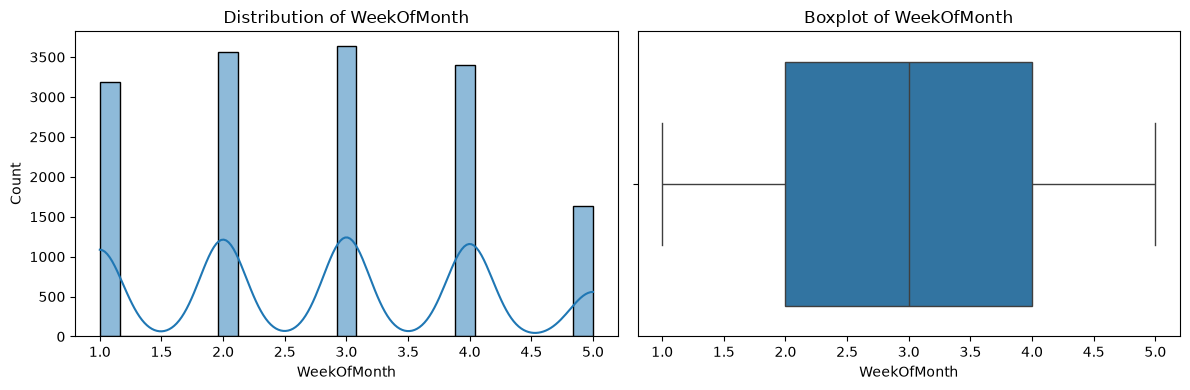

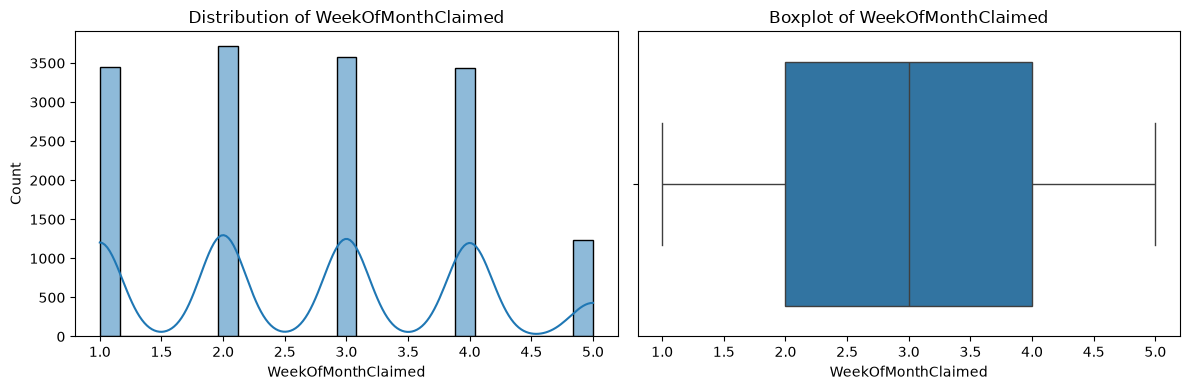

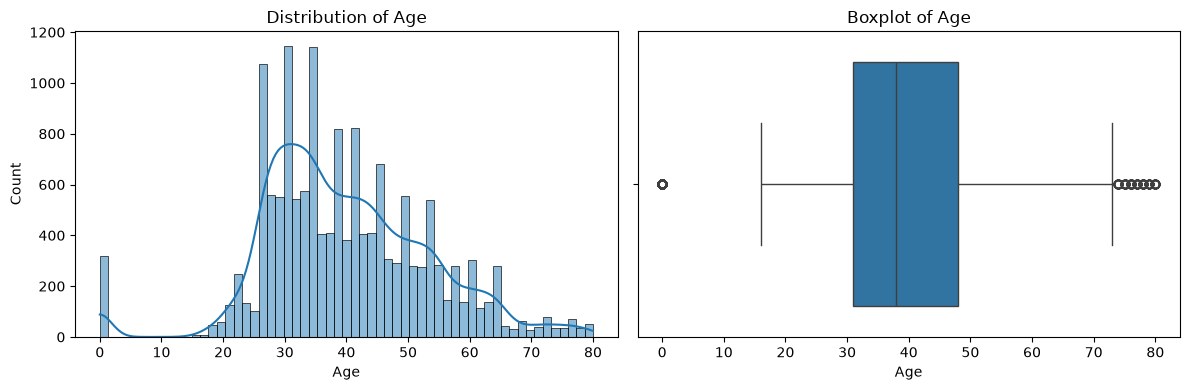

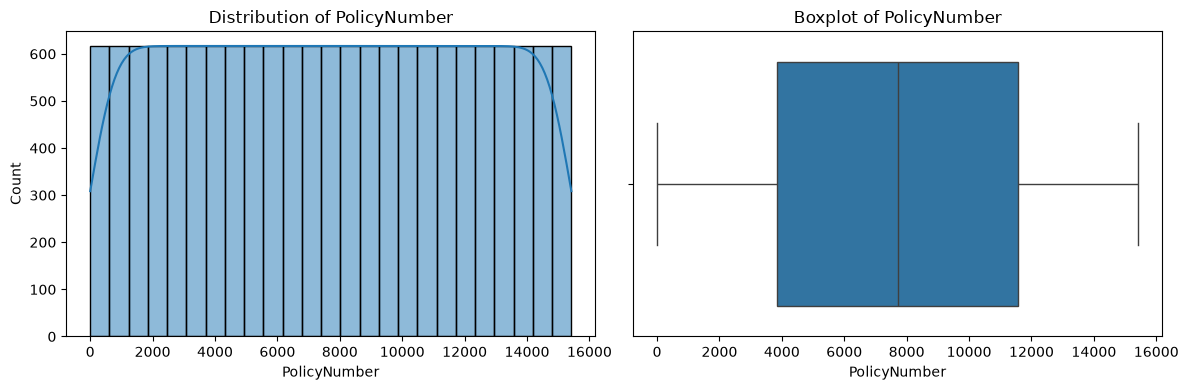

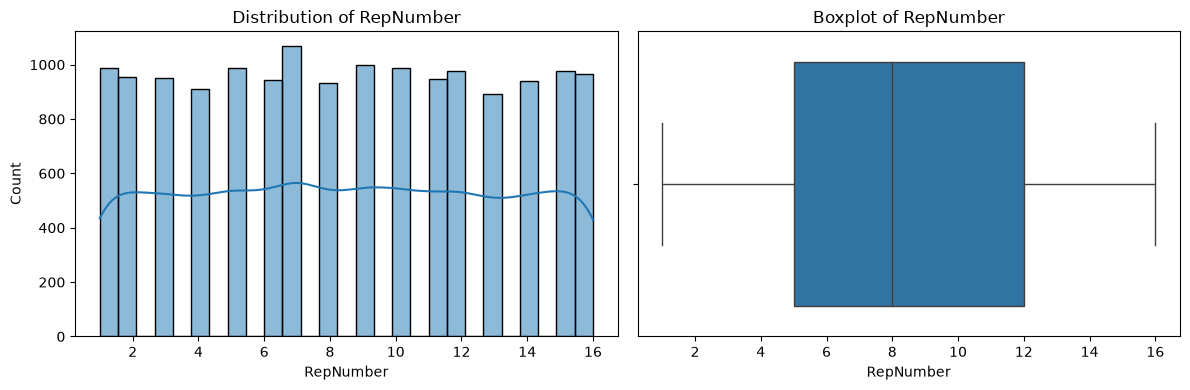

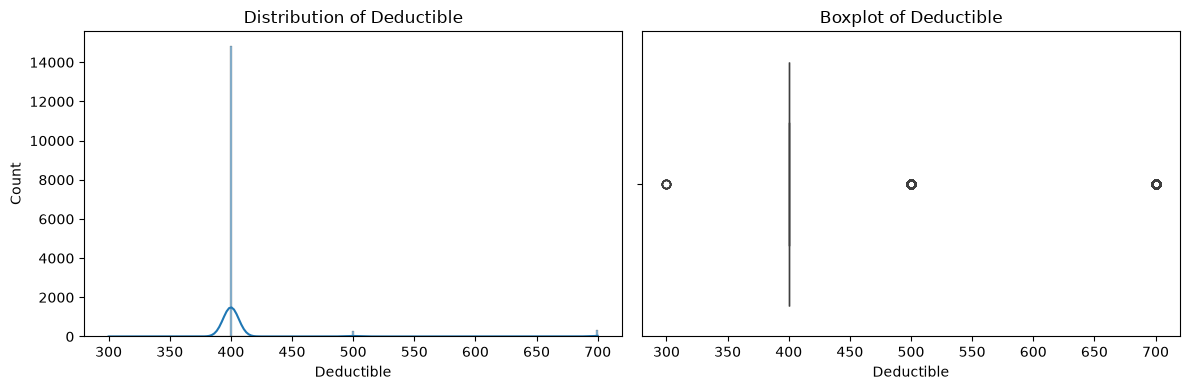

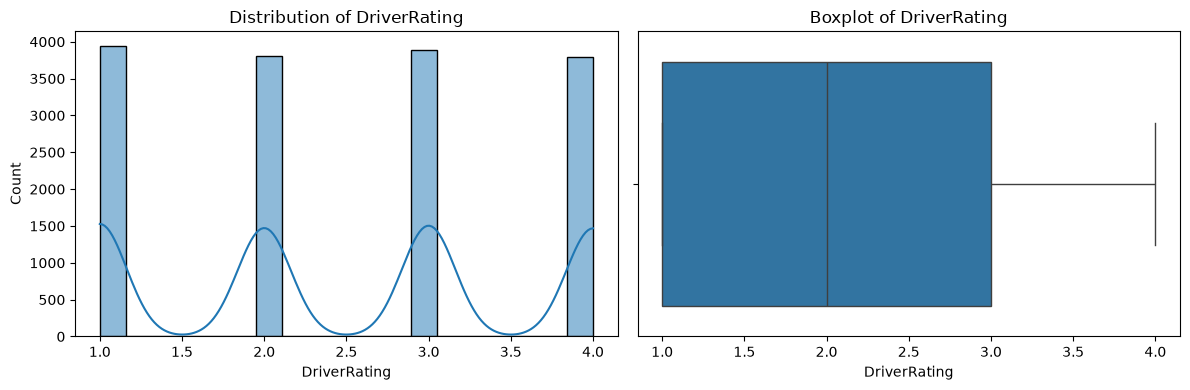

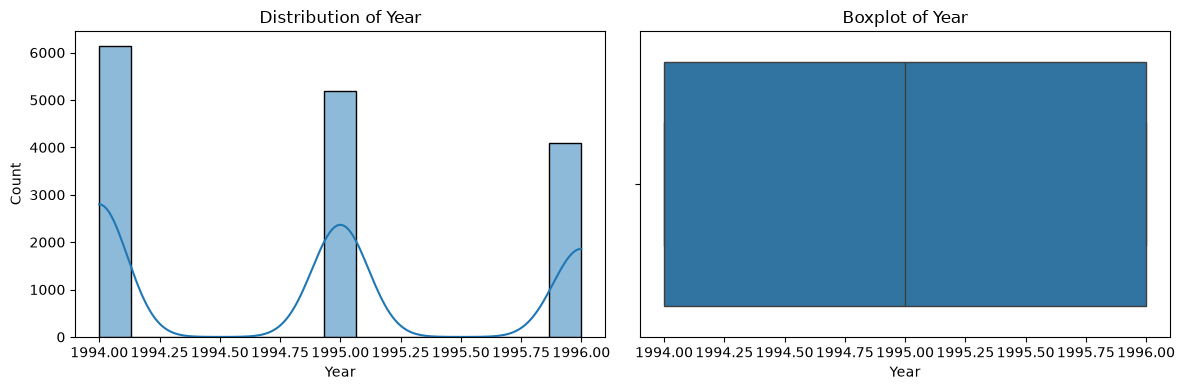

In [6]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include= ['object', 'category', 'bool']).columns.tolist()

# remove target --> we already know it is not numerical
numerical_cols.remove(TARGET)

print(df[numerical_cols].describe().T)
# Plot numerical feature distributions
for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=df, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(data=df, x=col, ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()


In [9]:
# categorical 
target = TARGET

for col in categorical_cols:
    fraud_rates = df.groupby(col, observed=True)[target].agg(
        Fraud_Rate= "mean",
        Claim_Count= "size"
    )
    # Calculates the fraud rate and claim count for each category in the specified column

    fraud_rates = fraud_rates.sort_values("Fraud_Rate", ascending=False)
    print(fraud_rates.head(15))

    # write this to our textoutputfile
    with open("testoutput.txt", "a") as f:
        f.write(f"Column: {col}\n")
        f.write(fraud_rates.head(15).to_string())
        f.write("\n")

       Fraud_Rate  Claim_Count
Month                         
Mar      0.075000         1360
Aug      0.074534         1127
May      0.068764         1367
Feb      0.064771         1266
Apr      0.062500         1280
Jan      0.061658         1411
Sep      0.061290         1240
Jun      0.060560         1321
Oct      0.053640         1305
Dec      0.048249         1285
Jul      0.047733         1257
Nov      0.038301         1201
           Fraud_Rate  Claim_Count
DayOfWeek                         
Sunday       0.069914         1745
Saturday     0.066599         1982
Friday       0.062986         2445
Monday       0.061162         2616
Thursday     0.055223         2173
Wednesday    0.053265         2159
Tuesday      0.052174         2300
           Fraud_Rate  Claim_Count
Make                              
Mecedes      0.250000            4
Accura       0.125000          472
Saturn       0.103448           58
Saab         0.101852          108
Ford         0.073333          450
Mercur